Daten geladen: (48895, 16)
Nach Bereinigung: (48586, 16)
Fehlende Werte:
 id                                   0
name                                16
host_id                              0
host_name                           21
neighbourhood_group                  0
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
last_review                       9890
reviews_per_month                    0
calculated_host_listings_count       0
availability_365                     0
dtype: int64
                 id       host_id      latitude     longitude         price  \
count  4.858600e+04  4.858600e+04  48586.000000  48586.000000  48586.000000   
mean   1.902135e+07  6.763733e+07     40.728927    -73.952031    140.269049   
std    1.097890e+07  7.860718e+07      0.054580     

C:\Users\okans\AppData\Local\Temp\ipykernel_7232\3981578255.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='neighbourhood_group', y='price', data=df, palette="pastel")


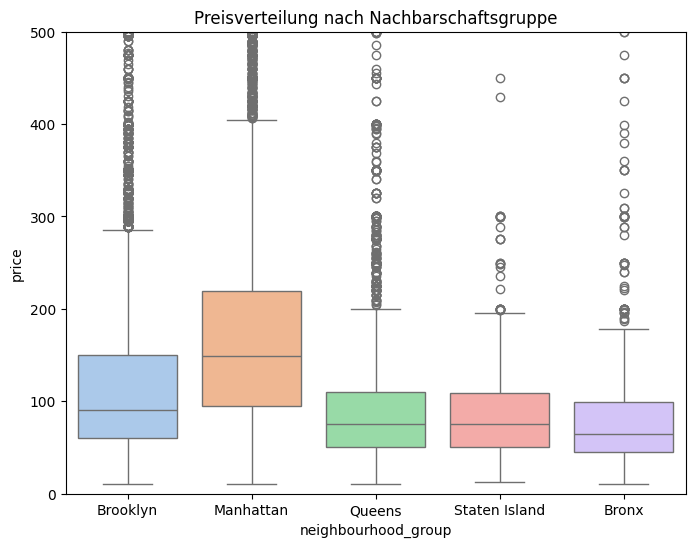

Karte gespeichert unter: C:\Users\okans\OneDrive\Pictures\Masaüstü\airbnb-data-analysis\output\nyc_map.html


In [1]:
# 01_eda_airbnb.ipynb

import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt
import folium

# ================================
# 1️⃣ Daten laden
# ================================
data_path = os.path.join(os.path.dirname(os.getcwd()), "data", "AB_NYC_2019.csv")
df = pd.read_csv(data_path)
print("Daten geladen:", df.shape)

# ================================
# 2️⃣ Datenbereinigung
# ================================
df.drop_duplicates(inplace=True)
df = df[df['price'] > 0]
df = df[df['price'] < 1000]
df = df.dropna(subset=['latitude', 'longitude'])
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

print("Nach Bereinigung:", df.shape)
print("Fehlende Werte:\n", df.isnull().sum())

# ================================
# 3️⃣ Grundanalyse
# ================================
print(df.describe())
print("Anzahl der Einträge je Nachbarschaftsgruppe:\n", df['neighbourhood_group'].value_counts())

# ================================
# 4️⃣ Boxplot: Preisverteilung
# ================================
plt.figure(figsize=(8,6))
sns.boxplot(x='neighbourhood_group', y='price', data=df, palette="pastel")
plt.ylim(0, 500)
plt.title("Preisverteilung nach Nachbarschaftsgruppe")
plt.show()

# ================================
# 5️⃣ Kartenvisualisierung
# ================================
m = folium.Map(location=[40.7128, -74.0060], zoom_start=10)
for _, row in df.sample(min(500, len(df))).iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=2,
        color='blue',
        fill=True
    ).add_to(m)

output_path = os.path.join(os.path.dirname(os.getcwd()), "output")
os.makedirs(output_path, exist_ok=True)
m.save(os.path.join(output_path, "nyc_map.html"))
print("Karte gespeichert unter:", os.path.join(output_path, "nyc_map.html"))
